# Lab 2

### Setup
Load the libraries and dataset.

In [1]:
%pip install numpy pandas matplotlib seaborn scipy tabulate --quiet

Note: you may need to restart the kernel to use updated packages.


In [2]:
import kagglehub
import pandas as pd
import os

# Download latest version
path = kagglehub.dataset_download("kanchana1990/adzuna-global-job-listings-2025")
file_path = os.path.join(path, os.listdir(path)[0])
df = pd.read_csv(file_path)

# Select only relevant columns
relevant_columns = [
    "title",
    "company",
    "created",
    "category_tag",
    "salary_min",
    "salary_max",
]
df = df[relevant_columns].dropna()

# Display the info about the dataframe
print(df.info())

# Define constants
p_value_threshold = 0.05
statistics = []

<class 'pandas.core.frame.DataFrame'>
Index: 17310 entries, 0 to 17349
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   title         17310 non-null  object 
 1   company       17310 non-null  object 
 2   created       17310 non-null  object 
 3   category_tag  17310 non-null  object 
 4   salary_min    17310 non-null  float64
 5   salary_max    17310 non-null  float64
dtypes: float64(2), object(4)
memory usage: 946.6+ KB
None


### Formulate a hypothesis & calculate the t-statistic

In [3]:
from scipy import stats
import numpy as np


salary_hypothesis_point = 78000
target_series = df["salary_min"]
mean, std, num = target_series.mean(), target_series.std(), target_series.count()

t_statistic = (mean - salary_hypothesis_point) / (std / (num**0.5))
print(f"T-statistic: {t_statistic}")

# Calculate the p-value for the t-statistic
p_value = 2 * stats.t.sf(np.abs(t_statistic), df=num - 1)
print(f"P-value: {p_value}")

# Store the results in the DataFrame
statistics.append(
    [
        f"Mean salary is {salary_hypothesis_point}",
        t_statistic,
        p_value,
        "Reject" if p_value < p_value_threshold else "Proceed",
    ]
)

# Compare with scipy ttest_1samp function
t_statistic_scipy, p_value_scipy = stats.ttest_1samp(
    target_series, salary_hypothesis_point
)
print(f"T-statistic (scipy): {t_statistic_scipy}")
print(f"P-value (scipy): {p_value_scipy}")

is_consistent = np.isclose(
    [t_statistic, p_value], [t_statistic_scipy, p_value_scipy]
).all()
print(f"\nAre the results consistent? {is_consistent}")

if p_value < p_value_threshold:
    print(f"Reject the null hypothesis at p < {p_value_threshold}")
else:
    print(
        f"Proceed with the null hypothesis at p >= {p_value_threshold} (p = {p_value})"
    )

T-statistic: -0.8146244673744896
P-value: 0.41529850827856507
T-statistic (scipy): -0.8146244673744895
P-value (scipy): 0.4152985082785655

Are the results consistent? True
Proceed with the null hypothesis at p >= 0.05 (p = 0.41529850827856507)


### Comparative analysis (between categories)

Top 10 Job Categories:
category_tag
it-jobs                          4499
healthcare-nursing-jobs          1863
sales-jobs                       1593
admin-jobs                       1112
pr-advertising-marketing-jobs     929
hr-jobs                           873
logistics-warehouse-jobs          869
hospitality-catering-jobs         847
teaching-jobs                     814
engineering-jobs                  746
Name: count, dtype: int64

Comparing categories: healthcare-nursing-jobs, sales-jobs
T-statistic: 0.9749849645143923
P-value: 0.3309029664099886
Proceed with the null hypothesis at p >= 0.05 (p = 0.3309029664099886)


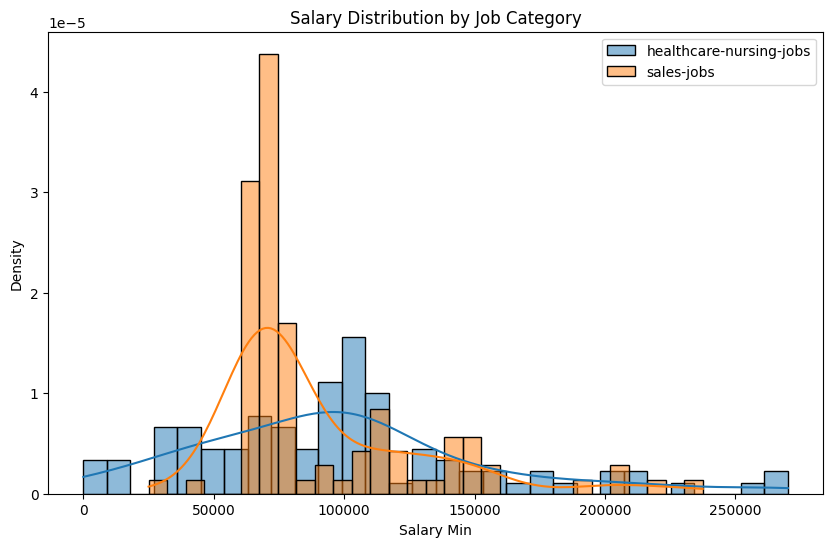

Comparing categories: sales-jobs, admin-jobs
T-statistic: 8.351471021406569
P-value: 4.529922098165059e-14
Reject the null hypothesis at p < 0.05


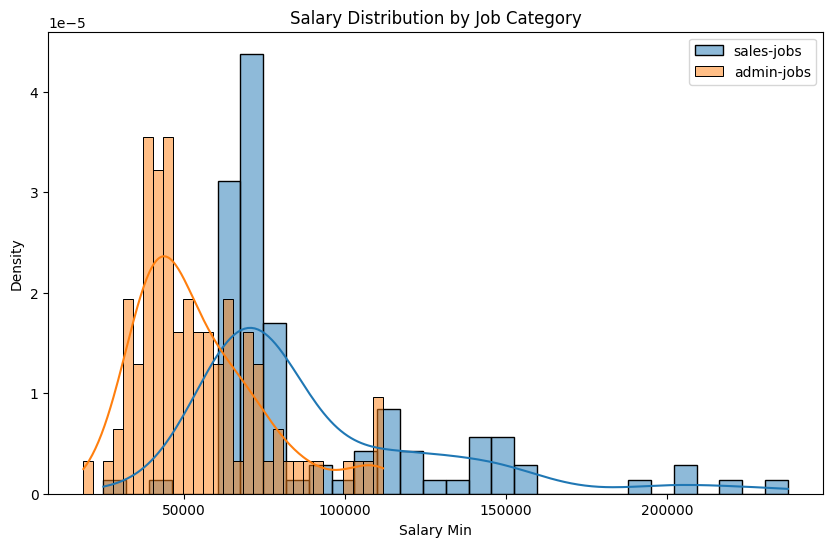


Summary of Statistical Tests:

| Hypothesis                                                       |   T-statistic |     P-value | Status   |
|:-----------------------------------------------------------------|--------------:|------------:|:---------|
| Mean salary is 78000                                             |     -0.814624 | 0.415299    | Proceed  |
| Salary difference between healthcare-nursing-jobs and sales-jobs |      0.974985 | 0.330903    | Proceed  |
| Salary difference between sales-jobs and admin-jobs              |      8.35147  | 4.52992e-14 | Reject   |


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns


target_series = df["category_tag"]
top_10_categories = target_series.value_counts().head(10)
print("Top 10 Job Categories:")
print(top_10_categories, end="\n\n")


# Calculate between-category statistics
def between_category_stats(target_categories):
    print(f"Comparing categories: {', '.join(target_categories)}")
    samples = {
        category: df[target_series == category].iloc[:100]
        for category in target_categories
    }
    t_statistic, p_value = stats.ttest_ind(
        samples[target_categories[0]]["salary_min"],
        samples[target_categories[1]]["salary_min"],
        equal_var=False,
    )
    statistics.append(
        [
            f"Salary difference between {target_categories[0]} and {target_categories[1]}",
            t_statistic,
            p_value,
            "Reject" if p_value < p_value_threshold else "Proceed",
        ]
    )
    print(f"T-statistic: {t_statistic}")
    print(f"P-value: {p_value}")

    if p_value < p_value_threshold:
        print(f"Reject the null hypothesis at p < {p_value_threshold}")
    else:
        print(
            f"Proceed with the null hypothesis at p >= {p_value_threshold} (p = {p_value})"
        )

    # Plot histograms
    plt.figure(figsize=(10, 6))
    for category, sample in samples.items():
        sns.histplot(
            sample["salary_min"],
            label=category,
            kde=True,
            stat="density",
            bins=30,
            alpha=0.5,
        )
    plt.legend()
    plt.title("Salary Distribution by Job Category")
    plt.xlabel("Salary Min")
    plt.ylabel("Density")
    plt.show()


between_category_stats(top_10_categories.index[1:3])
between_category_stats(top_10_categories.index[2:4])

statistics_df = pd.DataFrame(
    statistics, columns=["Hypothesis", "T-statistic", "P-value", "Status"]
)
print("\nSummary of Statistical Tests:", end="\n\n")
print(statistics_df.to_markdown(index=False))